# 02 · Pipeline: de MASTER a FS (las variables)

> **Qué haces tú:** ejecutar el cuaderno entero y leer lo que sale. No hay código que escribir.

## Objetivo
Construir la capa **FS** (*feature store*, «almacén de variables»): para cada lote, las **variables** que describen lo que sabemos de él, calculadas **una vez**,
**documentadas** y listas para reutilizar. Dos tablas:
- `fs_lote`: una fila por lote, una columna por variable.
- `fs_catalogo`: el «diccionario»: qué es cada variable, de dónde sale y **cuándo se conoce**.

### La regla de oro
> Una variable solo puede usar información que **se conozca al recibir el lote, antes de catarlo**.

Por eso FS **nunca lee las notas de cata ni la puntuación total**: las diez notas **suman** el total, así que usarlas sería **fuga de información**.
En este cuaderno lo **verificarás con una consulta**; la prueba automática del proyecto lo vigila además en cada ejecución.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160, 'display.max_columns', 30, 'display.max_colwidth', 70)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml». Así el cuaderno funciona se abra desde donde se abra.
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from cafe_mlops import config, db   # el paquete del proyecto: lo mismo que ejecutan las órdenes de la terminal

print('Proyecto listo.')
print('Base operacional:', config.DB_OPERACIONAL.name, '· base analítica:', config.DB.name)

con = db.conectar()
if not db.escalar(con, "SELECT COUNT(*) FROM sqlite_master WHERE type = 'table' AND name = 'master_lotes'"):
    raise FileNotFoundError('Falta master_lotes: ejecuta antes el cuaderno 01.')

from cafe_mlops import features

Proyecto listo.
Base operacional: cqi.db · base analítica: cafe.db


## 1. Construir FS
`features.construir_fs()` ejecuta `sql/fs/01_crear_fs.sql` (define las tablas) y `02_poblar_fs.sql` (las llena **solo desde `master_lotes`**).
Las variables que usa el modelo están en `config.FEATURES`: cinco categóricas (texto) y cinco numéricas.

In [2]:
features.construir_fs(con)
print()
print('Categóricas:', config.CATEGORICAS)
print('Numéricas:  ', config.NUMERICAS)

  FS: fs_lote 1,190 lotes, 10 variables (catálogo: 10)

Categóricas: ['especie', 'pais', 'variedad', 'metodo_proceso', 'color']
Numéricas:   ['altitud_media_m', 'humedad', 'defectos_cat1', 'defectos_cat2', 'quakers']


## 2. El catálogo: qué es cada variable y cuándo se conoce
Mira la columna `cuando_se_conoce`: **todas** dicen «al recibir el lote». Si alguna dijera «después de catar», no podría estar aquí.

In [3]:
with pd.option_context('display.max_colwidth', 70, 'display.width', 200):
    display(pd.read_sql('SELECT feature, tipo, descripcion, origen, cuando_se_conoce FROM fs_catalogo ORDER BY rowid', con))

,feature,tipo,descripcion,origen,cuando_se_conoce
0,especie,categorica,Arábica o robusta: protocolos de cata distintos,master_lotes.especie (Species),al recibir el lote
1,pais,categorica,País de origen del lote,master_lotes.pais (Country.of.Origin),al recibir el lote
2,variedad,categorica,Variedad del café (nula si no se informó),master_lotes.variedad (Variety),al recibir el lote
3,metodo_proceso,categorica,"Método de beneficio: lavado, natural... (nulo si no se informó)",master_lotes.metodo_proceso (Processing.Method),al recibir el lote
4,color,categorica,Color del grano verde (nulo si no se informó),master_lotes.color (Color),al recibir el lote
5,altitud_media_m,numerica,Altitud media de la finca; nula si falta o está fuera de 100–4 000 m,master_lotes.altitud_media_m (altitude_mean_meters),al recibir el lote
6,humedad,numerica,Humedad del grano verde; nula si no se midió (el 0 del origen),master_lotes.humedad (Moisture),al recibir el lote
7,defectos_cat1,numerica,Defectos de categoría 1 en la muestra de grano verde,master_lotes.defectos_cat1 (Category.One.Defects),al recibir el lote
8,defectos_cat2,numerica,Defectos de categoría 2 en la muestra de grano verde,master_lotes.defectos_cat2 (Category.Two.Defects),al recibir el lote
9,quakers,numerica,Granos «quaker» (inmaduros) en la muestra,master_lotes.quakers (Quakers),al recibir el lote


## 3. Las variables de algunos lotes
Una fila por lote. Fíjate en los **valores vacíos** (`None` / `NaN`): cuando un dato falta, **se deja nulo**; no se inventa un valor.
El modelo (cuaderno 04) los trata **dentro de su propio pipeline**, igual al entrenar que al servir.

In [4]:
pd.read_sql('SELECT * FROM fs_lote ORDER BY lote_id LIMIT 8', con)

,lote_id,especie,pais,variedad,metodo_proceso,color,altitud_media_m,humedad,defectos_cat1,defectos_cat2,quakers
0,1,Arabica,Ethiopia,None,Washed / Wet,Green,2075.0,0.12,0.0,0.0,0.0
1,2,Arabica,Ethiopia,Other,Washed / Wet,Green,2075.0,0.12,0.0,1.0,0.0
2,3,Arabica,Guatemala,Bourbon,None,None,1700.0,NaN,0.0,0.0,0.0
3,4,Arabica,Ethiopia,None,Natural / Dry,Green,2000.0,0.11,0.0,2.0,0.0
4,5,Arabica,Ethiopia,Other,Washed / Wet,Green,2075.0,0.12,0.0,2.0,0.0
5,6,Arabica,Brazil,None,Natural / Dry,Bluish-Green,NaN,0.11,0.0,1.0,0.0
6,7,Arabica,Peru,Other,Washed / Wet,Bluish-Green,NaN,0.11,0.0,0.0,0.0
7,8,Arabica,Ethiopia,None,None,None,1635.0,0.03,0.0,0.0,0.0


### ¿Cuántos valores faltan en cada variable?
Es información útil: una variable casi vacía aporta poco. (La altitud tiene más huecos porque MASTER dejó nulas las imposibles; la humedad, porque dejó nulos los ceros.)

,% de lotes sin dato
especie,0.0
defectos_cat1,0.0
defectos_cat2,0.0
pais,0.1
quakers,0.1
metodo_proceso,13.4
variedad,17.6
color,17.7
humedad,19.4
altitud_media_m,19.4


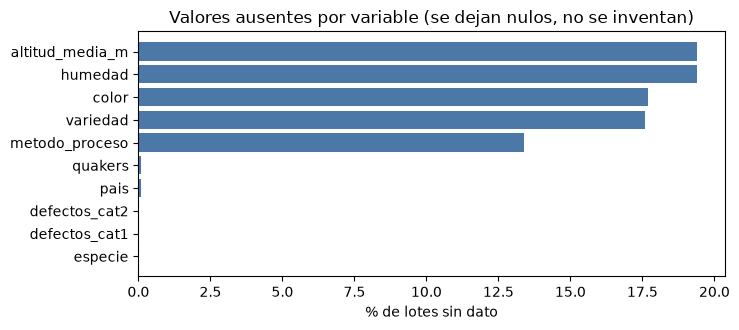

In [5]:
import matplotlib.pyplot as plt

fs = pd.read_sql('SELECT * FROM fs_lote', con)
faltan = (fs[config.FEATURES].isna().mean() * 100).round(1).sort_values()
display(faltan.rename('% de lotes sin dato').to_frame())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(faltan.index, faltan.values, color='#4C78A8')
ax.set_xlabel('% de lotes sin dato')
ax.set_title('Valores ausentes por variable (se dejan nulos, no se inventan)')
plt.tight_layout()
plt.show()

### Cómo son las variables de texto y las numéricas
Cuántas categorías distintas tiene cada variable de texto y cuál es la más frecuente; y el resumen de las numéricas.

In [6]:
categorias = pd.DataFrame({
    'categorías distintas': fs[config.CATEGORICAS].nunique(),
    'la más frecuente': fs[config.CATEGORICAS].mode().iloc[0],
    'lotes con esa': [int((fs[c] == fs[c].mode().iloc[0]).sum()) for c in config.CATEGORICAS],
})
display(categorias)
fs[config.NUMERICAS].describe().round(2)

,categorías distintas,la más frecuente,lotes con esa
especie,2,Arabica,1164
pais,35,Mexico,232
variedad,28,Caturra,216
metodo_proceso,5,Washed / Wet,720
color,4,Green,757


,altitud_media_m,humedad,defectos_cat1,defectos_cat2,quakers
count,959.00,959.00,1190.00,1190.00,1189.00
mean,1350.35,0.11,0.52,3.57,0.11
std,432.15,0.02,2.69,5.32,0.64
min,100.00,0.01,0.00,0.00,0.00
25%,1100.00,0.11,0.00,0.00,0.00
50%,1320.00,0.11,0.00,2.00,0.00
75%,1600.00,0.12,0.00,4.00,0.00
max,3850.00,0.28,63.00,47.00,9.00


## 4. Comprobar la regla de oro
Dos comprobaciones sobre las tablas reales:
1. **Ninguna columna de `fs_lote`** se llama como una nota de cata, como el total o como un dato personal.
2. Ninguna variable numérica, **por sí sola**, reproduce la puntuación total. Medimos la correlación de cada una con el total: debe ser baja. (Las notas sumadas, en cambio, **sí** la reproducen: lo verás en el cuaderno 03.)

In [7]:
def normalizar(nombre):
    return nombre.lower().replace('.', '_')


prohibidas = {normalizar(n) for n in config.TODAS_LAS_NOTAS} | {normalizar(config.COLUMNA_TOTAL), 'total_puntos', 'y'}
prohibidas |= {normalizar(n) for n in config.COLUMNAS_PERSONALES + config.COLUMNAS_FUERA_DEL_MODELO}
columnas = [c for c in fs.columns if c != 'lote_id']
colados = sorted(set(columnas) & prohibidas)
assert not colados, f'Columnas prohibidas en FS: {colados}'
print(f'Columnas de fs_lote: {columnas}')
print(f'Columnas prohibidas (notas, total, datos personales): {len(prohibidas)} nombres vigilados; encontradas en FS: {len(colados)}')

con_total = pd.read_sql('SELECT f.*, m.total_puntos FROM fs_lote f JOIN master_lotes m ON m.lote_id = f.lote_id', con)
correlaciones = pd.Series({c: con_total[[c, 'total_puntos']].dropna().corr().iloc[0, 1] for c in config.NUMERICAS}).round(3)
correlaciones.rename('correlación con el total').to_frame()

Columnas de fs_lote: ['especie', 'pais', 'variedad', 'metodo_proceso', 'color', 'altitud_media_m', 'humedad', 'defectos_cat1', 'defectos_cat2', 'quakers']
Columnas prohibidas (notas, total, datos personales): 32 nombres vigilados; encontradas en FS: 0


,correlación con el total
altitud_media_m,0.185
humedad,-0.156
defectos_cat1,-0.181
defectos_cat2,-0.274
quakers,0.028


In [8]:
con.close()

## Resumen
- FS guarda las **variables** de cada lote (`fs_lote`) y su **diccionario** (`fs_catalogo`), con el momento en que se conoce cada una.
- Todas se conocen **al recibir el lote**; ninguna sale de las notas de cata ni del total.
- Los datos que faltan se **dejan nulos**; no se inventan.

**Siguiente:** el cuaderno **03** añade el objetivo `y`, reparte los lotes por **tiempo** y demuestra qué pasaría si usáramos las notas.

## Para practicar
1. ¿Qué variable tiene más valores ausentes y por qué crees que pasa?
2. Si quisieras añadir una variable nueva (por ejemplo, el número de sacos del lote), ¿qué pregunta tendrías que hacerte antes de incluirla?